# Bab 5 — Learning Multiple Weights at a Time

**Acuan:** Trask, *Grokking Deep Learning*, Bab 5, hlm. 79–98. Contoh latihan dalam notebook ini adalah implementasi orisinal dengan data kecil/sintetis untuk menelusuri gradien dan dimensi.

**Tujuan belajar:** memperluas pembaruan satu bobot menjadi vektor dan matriks bobot, memahami *weight pressure*, serta menjelaskan efek membekukan parameter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

features = np.array([8.5, .65, 1.2])
weights = np.array([.10, .20, -.10])
target = 1.0
prediction = float(features @ weights)
print('Prediksi awal:', round(prediction, 3))

Prediksi awal: 0.86


## 1. Banyak input, satu output

Jika $\hat y=x^\top w$ dan $L=(\hat y-y)^2$, maka turunan terhadap seluruh bobot adalah $\nabla_wL=2(\hat y-y)x$. Jadi semua bobot menerima sinyal error yang sama tetapi dikalikan fitur yang terhubung dengannya. Input nol menghasilkan gradien nol untuk bobot itu pada contoh tersebut. Skala input besar menghasilkan langkah lebih besar; karena itu normalisasi dan learning rate saling berhubungan.

In [2]:
delta = prediction - target
gradient = 2 * delta * features
learning_rate = .001
new_weights = weights - learning_rate * gradient
new_loss = (features @ new_weights - target) ** 2
old_loss = (prediction - target) ** 2
print('Gradien per bobot:', gradient.round(4))
print('Bobot setelah update:', new_weights.round(4))
print('Loss:', round(old_loss, 6), '→', round(float(new_loss), 6))
assert new_loss < old_loss

Gradien per bobot: [-2.38  -0.182 -0.336]
Bobot setelah update: [ 0.1024  0.2002 -0.0997]
Loss: 0.0196 → 0.01422


## 2. Membekukan satu bobot

Jika sebuah bobot dibekukan, gradien efektifnya dibuat nol. Prediksi masih dapat berubah karena bobot lain diperbarui, tetapi ruang solusi menjadi lebih sempit. Dalam eksperimen nyata, membekukan bobot dapat dipakai untuk mengisolasi peran fitur/layer; satu contoh saja tidak cukup untuk menyimpulkan kepentingan fitur secara umum.

In [3]:
frozen_gradient = gradient.copy()
frozen_gradient[1] = 0.0
frozen_update = weights - learning_rate * frozen_gradient
print('Bobot ke-2 tetap:', weights[1], '→', frozen_update[1])
print('Prediksi dengan bobot beku:', round(float(features @ frozen_update), 4))
assert frozen_update[1] == weights[1]

Bobot ke-2 tetap: 0.2 → 0.2
Prediksi dengan bobot beku: 0.8806


## 3. Satu input, banyak output

Jika $\hat{\boldsymbol y}=x\boldsymbol w$ dan loss adalah jumlah squared errors, setiap output mempunyai delta sendiri. Gradien $2x(\hat{\boldsymbol y}-\boldsymbol y)$ tetap berbentuk vektor. Output yang targetnya berbeda dapat menarik bobot ke arah berbeda; tidak ada keharusan semua bobot bergerak searah.

In [4]:
single_input = .65
multi_weights = np.array([.3, .2, .9])
goals = np.array([1., 0., .2])
multi_prediction = single_input * multi_weights
multi_gradient = 2 * single_input * (multi_prediction - goals)
print('Prediksi:', multi_prediction.round(3))
print('Gradien:', multi_gradient.round(3))
assert multi_prediction.shape == goals.shape

Prediksi: [0.195 0.13  0.585]
Gradien: [-1.046  0.169  0.501]


## 4. Banyak input dan banyak output: matriks gradien

Untuk $n$ contoh, $X\in\mathbb R^{n\times d}$, $W\in\mathbb R^{d\times k}$, dan $Y\in\mathbb R^{n\times k}$. Kita definisikan $L=\frac1n\sum_{i,j}(XW-Y)_{ij}^2$; gradiennya $\nabla_W L=\frac{2}{n}X^\top(XW-Y)$. Faktor pembagi hanya $n$, bukan $nk$, karena loss yang dipilih menjumlahkan output per contoh. Konvensi loss yang berbeda menghasilkan faktor gradien berbeda dan perlu learning rate yang sesuai.

In [5]:
X = np.array([[1.,0.,0.], [0.,1.,0.], [0.,0.,1.],
              [1.,1.,0.], [1.,0.,1.], [0.,1.,1.]])
W_true = np.array([[.5,-.2], [-.3,.7], [.8,.1]])
Y = X @ W_true             # target sintetis, tanpa noise
rng = np.random.default_rng(5)
W = rng.normal(0, .25, size=(3, 2))

def loss_and_gradient(W):
    error = X @ W - Y
    return float(np.sum(error**2) / len(X)), 2 * X.T @ error / len(X)

loss0, grad0 = loss_and_gradient(W)
eps = 1e-6
probe = np.zeros_like(W); probe[0, 0] = eps
finite_difference = (loss_and_gradient(W + probe)[0] - loss_and_gradient(W - probe)[0]) / (2 * eps)
print('Shape X/W/Y/grad:', X.shape, W.shape, Y.shape, grad0.shape)
print('Gradien analitik vs numerik W[0,0]:', round(grad0[0,0], 6), round(finite_difference, 6))
assert np.isclose(grad0[0,0], finite_difference, atol=1e-6)

Shape X/W/Y/grad: (6, 3) (3, 2) (6, 2) (3, 2)
Gradien analitik vs numerik W[0,0]: -0.793176 -0.793176


## 5. Latih semua bobot dan baca hasil

Setiap langkah di bawah memakai seluruh dataset (*full batch*). Jika data mengandung noise atau train set kecil, loss training yang sangat rendah bisa berarti overfitting. Di sini target sengaja diciptakan oleh matriks linear yang sama, sehingga mendekati nol justru hasil yang diharapkan secara konstruksi—bukan bukti keunggulan model pada persoalan nyata.

Loss awal/akhir: 0.6625 0.0
Bobot terpelajari:
 [[ 0.5 -0.2]
 [-0.3  0.7]
 [ 0.8  0.1]]
Bobot pembuat target:
 [[ 0.5 -0.2]
 [-0.3  0.7]
 [ 0.8  0.1]]


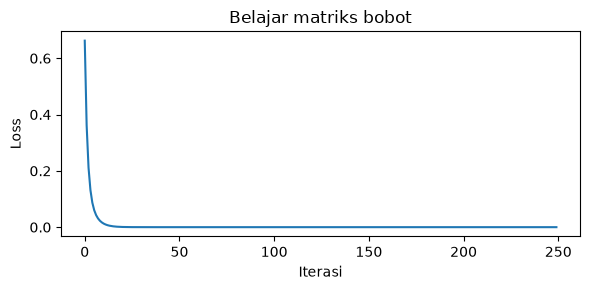

In [6]:
history = []
for _ in range(250):
    loss, grad = loss_and_gradient(W)
    history.append(loss)
    W -= .2 * grad
print('Loss awal/akhir:', round(history[0], 6), round(history[-1], 9))
print('Bobot terpelajari:\n', W.round(3))
print('Bobot pembuat target:\n', W_true)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(history); ax.set(xlabel='Iterasi', ylabel='Loss', title='Belajar matriks bobot')
plt.tight_layout(); plt.show()
assert np.allclose(W, W_true, atol=1e-3)

### Ringkasan dan refleksi

- Untuk satu output, gradien bobot sebanding dengan input dan error output.
- Untuk banyak output dan contoh, outer product/dot product menyatukan semua kontribusi dalam matriks.
- Pemeriksaan shape dan gradien numerik membantu menangkap bug yang sulit terlihat dari loss saja.
- Bobot yang besar tidak otomatis berarti fitur penting tanpa mempertimbangkan skala, korelasi antarf fitur, dan validasi data baru.